In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("../data/process/telco_customer_churn_cleaned.csv")

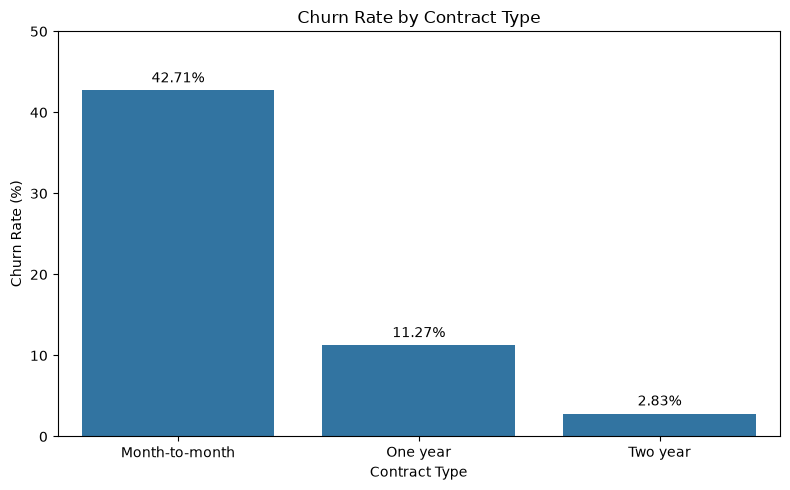

In [10]:
# Calculate churn rate
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
)

# Sort from highest to lowest
contract_churn = contract_churn.sort_values(
    by="Churn Rate",
    ascending=False
)

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn Rate"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(contract_churn["Churn Rate"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.savefig("../reports/churn_by_contract.png", dpi=300)
plt.show()

In [9]:
business_insights = df.groupby("Contract")["tenure"].mean()

print("Average Tenure by Contract Type:")
print(business_insights)

Average Tenure by Contract Type:
Contract
Month-to-month    18.036645
One year          42.044807
Two year          56.735103
Name: tenure, dtype: float64
